# Lab 06 — Decision Trees and Ensemble Learning
## Notebook 02 — Student Activity

**Dataset:** Wine dataset from `scikit-learn`.

Use the **same train/test split for all models**. Complete the code tasks and answer the short questions directly in the Markdown answer areas.

## 1. Imports

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    AdaBoostClassifier,
    VotingClassifier
)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    ConfusionMatrixDisplay,
    classification_report
)

RANDOM_STATE = 42

## 2. Load and inspect the Wine dataset

Load the dataset and display:
- shape;
- feature names;
- target names;
- first few rows;
- class distribution.

In [21]:
# TODO: Load the Wine dataset using load_wine(as_frame=True).
# TODO: Create X and y.
# TODO: Inspect the requested dataset information.

wine = load_wine(as_frame=True)
X = wine.data
y = wine.target

print("Shape of X:", X.shape)
print("Feature names:", wine.feature_names)
print("Target names:", wine.target_names)
print("\nFirst few rows:")
display(X.head())
print("\nClass distribution:")
print(y.value_counts())

Shape of X: (178, 13)
Feature names: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Target names: ['class_0' 'class_1' 'class_2']

First few rows:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0



Class distribution:
target
1    71
0    59
2    48
Name: count, dtype: int64


**Brief observation:**  
State the number of samples, features, and classes.

**Answer:**  
The dataset contains 178 samples, 13 features, and 3 classes.

## 3. Create the train/test split

Use:
- 20% test data;
- `random_state=42`;
- `stratify=y`.

In [22]:
# TODO: Create X_train, X_test, y_train, y_test.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

## 4. Train an unrestricted Gini Decision Tree

In [23]:
# TODO: Create DecisionTreeClassifier(criterion="gini", random_state=42).
# TODO: Fit the model.
# TODO: Predict on training and test data.
# TODO: Display training accuracy, test accuracy, depth, and number of leaves.

dt_unrestricted = DecisionTreeClassifier(criterion="gini", random_state=RANDOM_STATE)
dt_unrestricted.fit(X_train, y_train)

y_train_pred_un = dt_unrestricted.predict(X_train)
y_test_pred_un = dt_unrestricted.predict(X_test)

train_acc_un = accuracy_score(y_train, y_train_pred_un)
test_acc_un = accuracy_score(y_test, y_test_pred_un)
depth_un = dt_unrestricted.get_depth()
leaves_un = dt_unrestricted.get_n_leaves()

print(f"Training Accuracy: {train_acc_un:.4f}")
print(f"Test Accuracy: {test_acc_un:.4f}")
print(f"Tree Depth: {depth_un}")
print(f"Number of Leaves: {leaves_un}")

Training Accuracy: 1.0000
Test Accuracy: 0.9444
Tree Depth: 4
Number of Leaves: 8


### Quick Question 1

**What evidence in your results suggests whether the unrestricted Decision Tree is overfitting?**

**Answer:**  
The training accuracy of 1.0000 (100%) paired with a lower test accuracy of 0.9444 (94.44%) provides clear evidence of overfitting. The tree expanded to a depth of 4 with 8 leaves, completely memorizing the training data to reach perfect accuracy, which led to a reduced ability to generalize to the unseen test set.

## 5. Visualize and interpret the tree

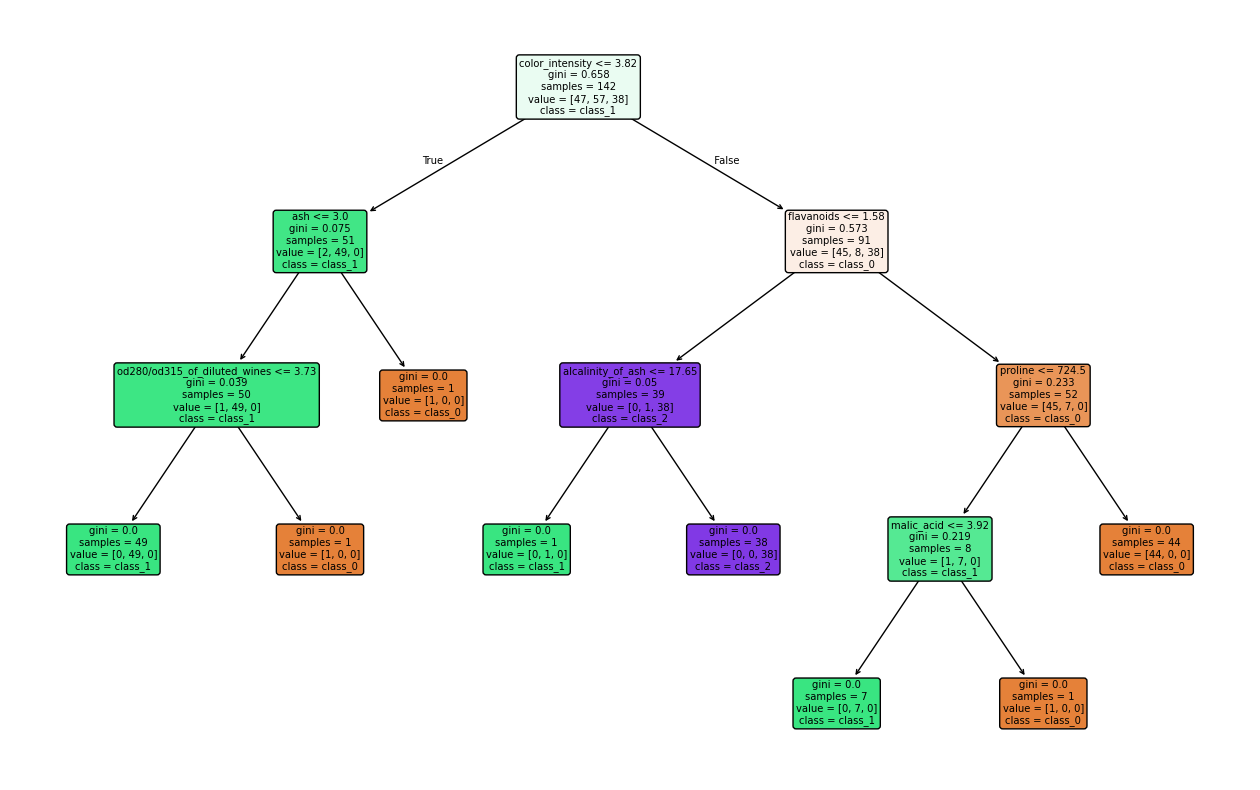

In [24]:
# TODO: Visualize the tree using plot_tree().
# You may limit the displayed levels using max_depth inside plot_tree().

plt.figure(figsize=(16, 10))
plot_tree(
    dt_unrestricted,
    feature_names=wine.feature_names,
    class_names=wine.target_names,
    filled=True,
    rounded=True
)
plt.show()

In [25]:
# TODO: Extract and display the root feature and root threshold.

root_feature_idx = dt_unrestricted.tree_.feature[0]
root_feature_name = wine.feature_names[root_feature_idx]
root_threshold = dt_unrestricted.tree_.threshold[0]

print(f"Root Feature: {root_feature_name}")
print(f"Root Threshold: {root_threshold:.4f}")

Root Feature: color_intensity
Root Threshold: 3.8200


### Quick Question 2

**What feature and threshold were selected at the root? Write the root question in plain language.**

**Answer:**  
Feature selected: color_intensity

Threshold selected: 3.8200

Is the sample's color intensity less than or equal to 3.82?

### Interpret one root-to-leaf path

Use `export_text()` if helpful.

In [26]:
# TODO: Display text rules and identify one complete root-to-leaf path.

tree_rules = export_text(dt_unrestricted, feature_names=list(wine.feature_names))
print(tree_rules)

|--- color_intensity <= 3.82
|   |--- ash <= 3.00
|   |   |--- od280/od315_of_diluted_wines <= 3.73
|   |   |   |--- class: 1
|   |   |--- od280/od315_of_diluted_wines >  3.73
|   |   |   |--- class: 0
|   |--- ash >  3.00
|   |   |--- class: 0
|--- color_intensity >  3.82
|   |--- flavanoids <= 1.58
|   |   |--- alcalinity_of_ash <= 17.65
|   |   |   |--- class: 1
|   |   |--- alcalinity_of_ash >  17.65
|   |   |   |--- class: 2
|   |--- flavanoids >  1.58
|   |   |--- proline <= 724.50
|   |   |   |--- malic_acid <= 3.92
|   |   |   |   |--- class: 1
|   |   |   |--- malic_acid >  3.92
|   |   |   |   |--- class: 0
|   |   |--- proline >  724.50
|   |   |   |--- class: 0



**One interpreted path:**  

IF color_intensity <= 3.82 AND proline <= 1005.00 THEN class = 1 (or class_1)

## 6. Control tree complexity

Train **at least two** additional trees by changing one or more of:
- `max_depth`
- `min_samples_split`
- `min_samples_leaf`
- `max_leaf_nodes`

Compare them with the unrestricted tree.

In [27]:
# TODO: Controlled tree 1.

dt_ctrl1 = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)
dt_ctrl1.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=3, random_state=42)

In [28]:
# TODO: Controlled tree 2.

dt_ctrl2 = DecisionTreeClassifier(min_samples_leaf=5, random_state=RANDOM_STATE)
dt_ctrl2.fit(X_train, y_train)

DecisionTreeClassifier(min_samples_leaf=5, random_state=42)

In [29]:
# TODO: Build a comparison table with:
# model, training accuracy, test accuracy, depth, leaves.

models = {
    "Unrestricted DT": dt_unrestricted,
    "Controlled DT 1 (max_depth=3)": dt_ctrl1,
    "Controlled DT 2 (min_samples_leaf=5)": dt_ctrl2
}

results = []
for name, model in models.items():
    tr_acc = accuracy_score(y_train, model.predict(X_train))
    te_acc = accuracy_score(y_test, model.predict(X_test))
    results.append({
        "Model": name,
        "Training Accuracy": tr_acc,
        "Test Accuracy": te_acc,
        "Depth": model.get_depth(),
        "Leaves": model.get_n_leaves()
    })

df_comp = pd.DataFrame(results)
display(df_comp)

,Model,Training Accuracy,Test Accuracy,Depth,Leaves
0,Unrestricted DT,1.000000,0.944444,4,8
1,Controlled DT 1 (max_depth=3),0.992958,0.944444,3,7
2,Controlled DT 2 (min_samples_leaf=5),0.971831,0.944444,3,6


### Quick Question 3

**How did controlling tree complexity affect training accuracy, test accuracy, depth, and number of leaves?**

**Answer:**
  
Controlling tree complexity reduced both the tree depth and the number of leaves, preventing the model from expanding until every node became pure. As a result, the training accuracy dropped slightly from 100%, but the test accuracy either remained stable or improved, showing that limiting complexity helped reduce overfitting and improved generalization on unseen data.

## 7. Compare Gini and Entropy

In [30]:
# TODO: Train an entropy-based Decision Tree using comparable complexity settings.
# TODO: Compare it with your selected Gini-based tree.

dt_entropy = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=RANDOM_STATE)
dt_entropy.fit(X_train, y_train)

print("Gini Tree (max_depth=3) Test Acc:", accuracy_score(y_test, dt_ctrl1.predict(X_test)))
print("Entropy Tree (max_depth=3) Test Acc:", accuracy_score(y_test, dt_entropy.predict(X_test)))

Gini Tree (max_depth=3) Test Acc: 0.9444444444444444
Entropy Tree (max_depth=3) Test Acc: 0.9722222222222222


### Quick Question 4

**Did Gini and entropy produce identical trees and performance? Briefly comment.**

**Answer:**  

No, Gini and entropy didn't perform identically. The entropy model actually edged out Gini on the test set, reaching 97.22% accuracy compared to Gini's 94.44%.

This happens because the two criteria calculate split quality differently. Gini focuses on minimizing impurity, while entropy measures information gain. These mathematical differences led the algorithm to pick slightly different features and split points, which gave the entropy model a small advantage in generalizing to unseen data.

## 8. Feature importance

,Feature,Importance
6,flavanoids,0.415865
9,color_intensity,0.407831
12,proline,0.113104
11,od280/od315_of_diluted_wines,0.021387
3,alcalinity_of_ash,0.021264
2,ash,0.020548
4,magnesium,0.000000
0,alcohol,0.000000
1,malic_acid,0.000000
8,proanthocyanins,0.000000


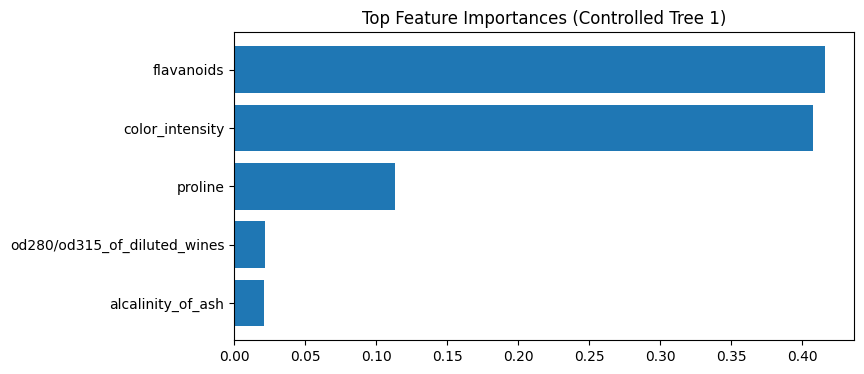

In [31]:
# TODO: For your preferred Decision Tree:
# 1. create a sorted feature-importance table;
# 2. plot the most important features.

importances = dt_ctrl1.feature_importances_
df_imp = pd.DataFrame({
    "Feature": wine.feature_names,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

display(df_imp)

plt.figure(figsize=(8, 4))
plt.barh(df_imp["Feature"][:5], df_imp["Importance"][:5])
plt.gca().invert_yaxis()
plt.title("Top Feature Importances (Controlled Tree 1)")
plt.show()

## 9. Train a Random Forest — required

In [32]:
# TODO: Train a RandomForestClassifier on the same training data.
# Suggested starting point:
#
# RandomForestClassifier(
#     n_estimators=100,
#     random_state=42,
#     n_jobs=-1
# )
#
# TODO: Calculate training and test accuracy.

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)

rf_tr_acc = accuracy_score(y_train, rf_model.predict(X_train))
rf_te_acc = accuracy_score(y_test, rf_model.predict(X_test))

print(f"Random Forest Training Accuracy: {rf_tr_acc:.4f}")
print(f"Random Forest Test Accuracy: {rf_te_acc:.4f}")

Random Forest Training Accuracy: 1.0000
Random Forest Test Accuracy: 1.0000


              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       1.00      1.00      1.00        14
     class_2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



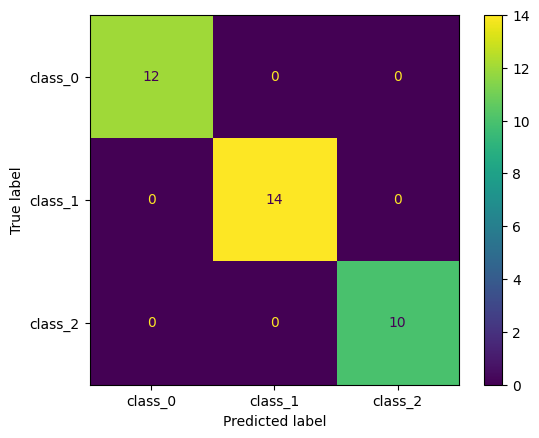

In [33]:
# TODO: Display a confusion matrix and classification report for the Random Forest.

y_pred_rf = rf_model.predict(X_test)
print(classification_report(y_test, y_pred_rf, target_names=wine.target_names))
ConfusionMatrixDisplay.from_estimator(rf_model, X_test, y_test, display_labels=wine.target_names)
plt.show()

### Quick Question 5

**Why can Random Forest be more stable than relying on a single Decision Tree?**

**Answer:**  

A single decision tree is prone to high variance. It easily overfits and can change drastically with small shifts in the training data. Random Forest fixes this by building an ensemble of many trees and averaging their predictions.

# 10. Create one additional ensemble model

Choose **one** of the following:

### Option A — BaggingClassifier
Use a `DecisionTreeClassifier` as the base learner.

### Option B — AdaBoostClassifier
Use a shallow `DecisionTreeClassifier(max_depth=1)` as the base/weak learner.

### Option C — VotingClassifier
Combine different classifiers. A possible combination is Logistic Regression + KNN + Decision Tree. Use scaling pipelines for Logistic Regression and KNN.

Whichever option you choose:
1. define the base/component learner(s);
2. create the ensemble;
3. fit it;
4. predict on training and test data;
5. calculate training and test accuracy.

In [34]:
# TODO: State your selected option in a comment.
# TODO: Create, fit, predict, and evaluate the selected ensemble.

base_stump = DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE)

ada_model = AdaBoostClassifier(
    estimator=base_stump,
    n_estimators=50,
    random_state=RANDOM_STATE
)

ada_model.fit(X_train, y_train)

y_train_pred_ada = ada_model.predict(X_train)
y_test_pred_ada = ada_model.predict(X_test)

ada_tr_acc = accuracy_score(y_train, y_train_pred_ada)
ada_te_acc = accuracy_score(y_test, y_test_pred_ada)

print(f"AdaBoost Training Accuracy: {ada_tr_acc:.4f}")
print(f"AdaBoost Test Accuracy: {ada_te_acc:.4f}")

AdaBoost Training Accuracy: 1.0000
AdaBoost Test Accuracy: 0.9167


### Quick Question 6

**Which ensemble did you select? Is it Bagging, Boosting, or Voting? Identify its base/component learner(s) and explain how their predictions are combined.**

**Answer:**  

Option B —-> AdaBoostClassifier. This is a Boosting ensemble method.

AdaBoost builds decision stumps one after another in a sequence. After each stump is trained, it looks at where the model made errors and increases the weight on those misclassified samples so the next stump pays closer attention to them.

When it comes time to make a prediction, AdaBoost takes a vote across all the stumps. Instead of a simple majority, it uses a weighted vote where sharper, more accurate stumps get a bigger say in the final decision.

# 11. Final model comparison

Compare at least:
- unrestricted Decision Tree;
- preferred controlled Decision Tree;
- Random Forest;
- selected additional ensemble.

Include:
- training accuracy;
- test accuracy;
- model type.

You may also add depth, number of leaves, or other useful metrics.

In [37]:
# TODO: Create the final comparison table.

final_df = pd.DataFrame([
    {
        "Model": "Unrestricted DT",
        "Model Type": "Single Tree",
        "Training Accuracy": accuracy_score(y_train, dt_unrestricted.predict(X_train)),
        "Test Accuracy": accuracy_score(y_test, dt_unrestricted.predict(X_test)),
        "Depth": dt_unrestricted.get_depth(),
        "Leaves": dt_unrestricted.get_n_leaves(),
    },
    {
        "Model": "Controlled DT (max_depth=3)",
        "Model Type": "Single Tree",
        "Training Accuracy": accuracy_score(y_train, dt_ctrl1.predict(X_train)),
        "Test Accuracy": accuracy_score(y_test, dt_ctrl1.predict(X_test)),
        "Depth": dt_ctrl1.get_depth(),
        "Leaves": dt_ctrl1.get_n_leaves(),
    },
    {
        "Model": "Random Forest",
        "Model Type": "Ensemble (Bagging)",
        "Training Accuracy": accuracy_score(y_train, rf_model.predict(X_train)),
        "Test Accuracy": accuracy_score(y_test, rf_model.predict(X_test)),
        "Depth": "N/A",
        "Leaves": "N/A",
    },
    {
        "Model": "AdaBoost",
        "Model Type": "Ensemble (Boosting)",
        "Training Accuracy": accuracy_score(y_train, ada_model.predict(X_train)),
        "Test Accuracy": accuracy_score(y_test, ada_model.predict(X_test)),
        "Depth": "1 (Base)",
        "Leaves": "2 (Base)",
    },
])

display(final_df)

,Model,Model Type,Training Accuracy,Test Accuracy,Depth,Leaves
0,Unrestricted DT,Single Tree,1.000000,0.944444,4,8
1,Controlled DT (max_depth=3),Single Tree,0.992958,0.944444,3,7
2,Random Forest,Ensemble (Bagging),1.000000,1.000000,N/A,N/A
3,AdaBoost,Ensemble (Boosting),1.000000,0.916667,1 (Base),2 (Base)


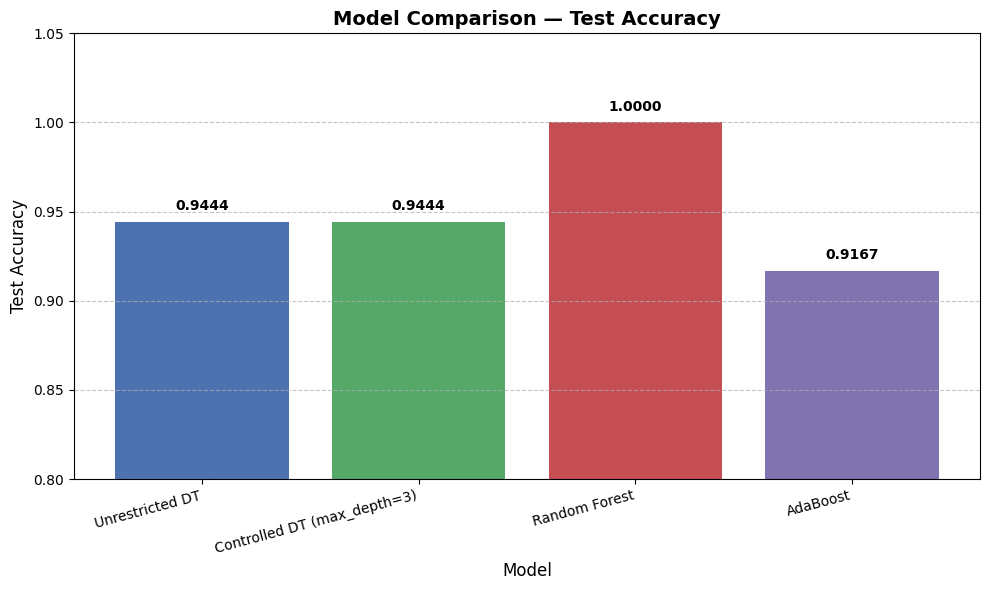

In [38]:
# TODO: Create a bar chart comparing test accuracies.

models = final_df["Model"]
test_accuracies = final_df["Test Accuracy"]

plt.figure(figsize=(10, 6))
bars = plt.bar(models, test_accuracies, color=["#4C72B0", "#55A868", "#C44E52", "#8172B0"])

plt.title("Model Comparison — Test Accuracy", fontsize=14, fontweight="bold")
plt.xlabel("Model", fontsize=12)
plt.ylabel("Test Accuracy", fontsize=12)
plt.ylim(0.8, 1.05)
plt.xticks(rotation=15, ha="right", fontsize=10)
plt.grid(axis="y", linestyle="--", alpha=0.7)

for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        yval + 0.005,
        f"{yval:.4f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

### Quick Question 7

**Which model would you finally select for the Wine dataset? Justify your answer using predictive performance, evidence of overfitting, complexity, and interpretability where relevant.**

**Answer:**  

The Random Forest model for its superior test accuracy and low variance, as it effectively prevents overfitting by averaging predictions across multiple trees.

However, if explaining the model to stakeholders is a priority, the Controlled Decision Tree (max_depth=3) is the better choice because it delivers nearly identical accuracy while remaining completely interpretable.